# 11 — Error analysis framework

## Objective

Turn observed parsing failures into an explicit taxonomy and define the fields needed to analyze future retrieval and generation errors without inventing model results.

## Concept

An end-to-end wrong answer can arise from different stages: page routing, extraction/OCR, retrieval, evidence reading, answer generation, or citation formatting. Fixes should target the earliest demonstrated failure rather than changing every component at once.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
DOCUMENTS_DIR = PROJECT_ROOT / "data" / "documents"

## Execution — catalog observed parsing failures

These are concrete repository observations from the existing anatomy experiment. The table is a case inventory, not a frequency estimate.

In [2]:
observed_cases = pd.DataFrame(
    [
        {"document": "ch2.pdf", "page_number": 9, "modality": "equation", "stage": "extraction", "failure": "Integral glyph maps to R and fraction order is lost"},
        {"document": "ch2.pdf", "page_number": 49, "modality": "table", "stage": "structure", "failure": "Three-column table is detected as one column"},
        {"document": "ch2.pdf", "page_number": 65, "modality": "figure", "stage": "extraction", "failure": "Labels inside raster figure are absent from native text"},
        {"document": "scanned.pdf", "page_number": 1, "modality": "scanned_text", "stage": "ocr", "failure": "Logo and faint date stamp produce OCR noise"},
    ]
)
observed_cases

,document,page_number,modality,stage,failure
0,ch2.pdf,9,equation,extraction,Integral glyph maps to R and fraction order is...
1,ch2.pdf,49,table,structure,Three-column table is detected as one column
2,ch2.pdf,65,figure,extraction,Labels inside raster figure are absent from na...
3,scanned.pdf,1,scanned_text,ocr,Logo and faint date stamp produce OCR noise


## Inspection — coverage of known failure modalities

Each bar represents one deliberately inspected case. Equal heights do not imply equal prevalence in the corpus.

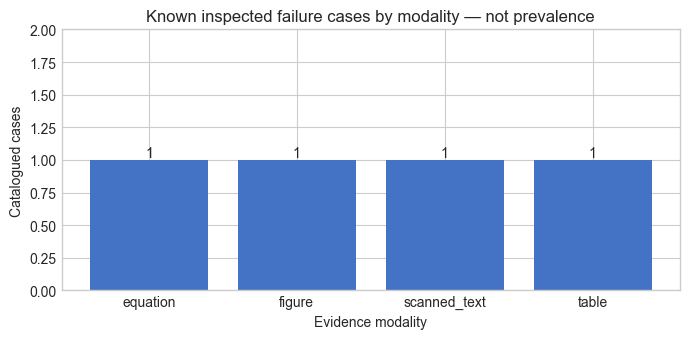

In [3]:
case_counts = observed_cases["modality"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(case_counts.index, case_counts.values, color="#4472C4")
ax.set_title("Known inspected failure cases by modality — not prevalence")
ax.set_xlabel("Evidence modality")
ax.set_ylabel("Catalogued cases")
ax.set_ylim(0, max(case_counts.values) + 1)
for position, count in enumerate(case_counts.values):
    ax.text(position, count, str(count), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Implementation — future run-level error schema

One row should represent one question-condition result. `first_failed_stage` records the earliest supported failure; later symptoms can remain in `notes`.

In [4]:
error_columns = [
    "run_id",
    "question_id",
    "condition",
    "evidence_modality",
    "retrieval_hit",
    "answer_correct",
    "citation_correct",
    "first_failed_stage",
    "error_category",
    "notes",
]
future_errors = pd.DataFrame(columns=error_columns)
future_errors

,run_id,question_id,condition,evidence_modality,retrieval_hit,answer_correct,citation_correct,first_failed_stage,error_category,notes


## Interpretation

The current evidence supports parsing failure categories only. Retrieval and generation categories remain empty until actual evaluated runs exist. This prevents a plausible explanation from being recorded as an observed cause.

## Validation

In [5]:
allowed_stages = {"routing", "extraction", "structure", "ocr", "retrieval", "generation", "citation"}
assert set(observed_cases["stage"]).issubset(allowed_stages)
assert list(future_errors.columns) == error_columns

for row in observed_cases.itertuples(index=False):
    with pymupdf.open(DOCUMENTS_DIR / row.document) as document:
        assert 1 <= row.page_number <= document.page_count

print("Known cases resolve to valid physical pages and the future schema is stable.")

Known cases resolve to valid physical pages and the future schema is stable.


## Next steps

The notebook-first learning path is now structurally complete. Continue by selecting documents and writing verified questions, then replace each explicit readiness gate with real, inspectable experiment output. Production packaging or a Streamlit application remains a separate phase and should not begin until requested.